<a href="https://colab.research.google.com/github/febrianucup/PCVK-CItra-Vision-Computer/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

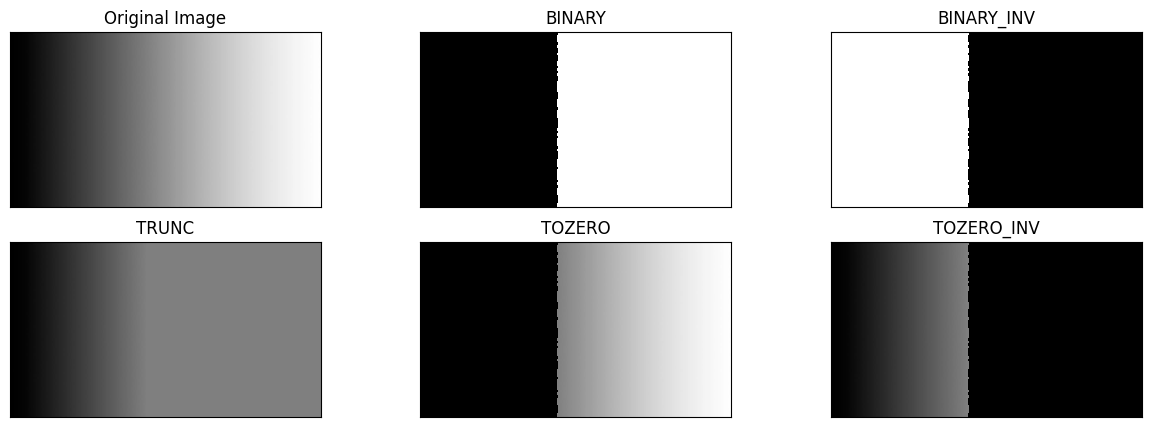

In [3]:
filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')
img = cv.imread(filename)
thresh = 127
#nilai Threshold yang ditentukan
maxval=255
#1. threshold binary jika pixel di img>127, maka thresh1 bernilai 1(putih) selain itu bernilai 0(hitam)
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)
#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)
#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)
#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)
#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)
titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO',
'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]
plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

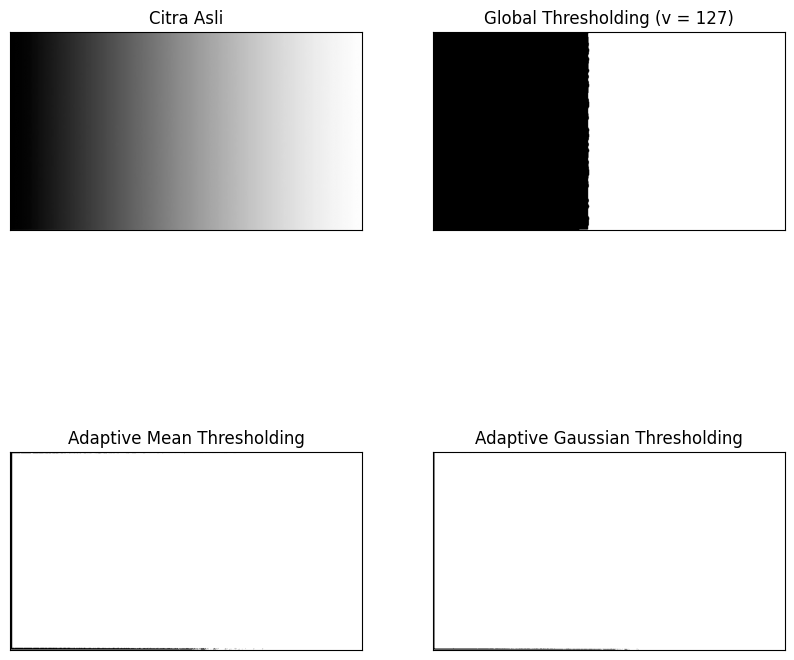

In [4]:
ilename = ('/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filename),5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)
thresh = 127
ret,th1 = cv.threshold(gray,thresh,255,cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_MEAN_C,
cv.THRESH_BINARY,11,2)
th3 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_GAUSSIAN_C,
cv.THRESH_BINARY,11,2)
titles = ['Citra Asli', 'Global Thresholding (v = 127)',
'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
citra2 = [gray, th1, th2, th3]
plt.figure(figsize = (10,10))
for i in range(len(citra2)):
  plt.subplot(2,2,i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

/tmp/ipykernel_1054/112085741.py:17: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_1054/112085741.py:18: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


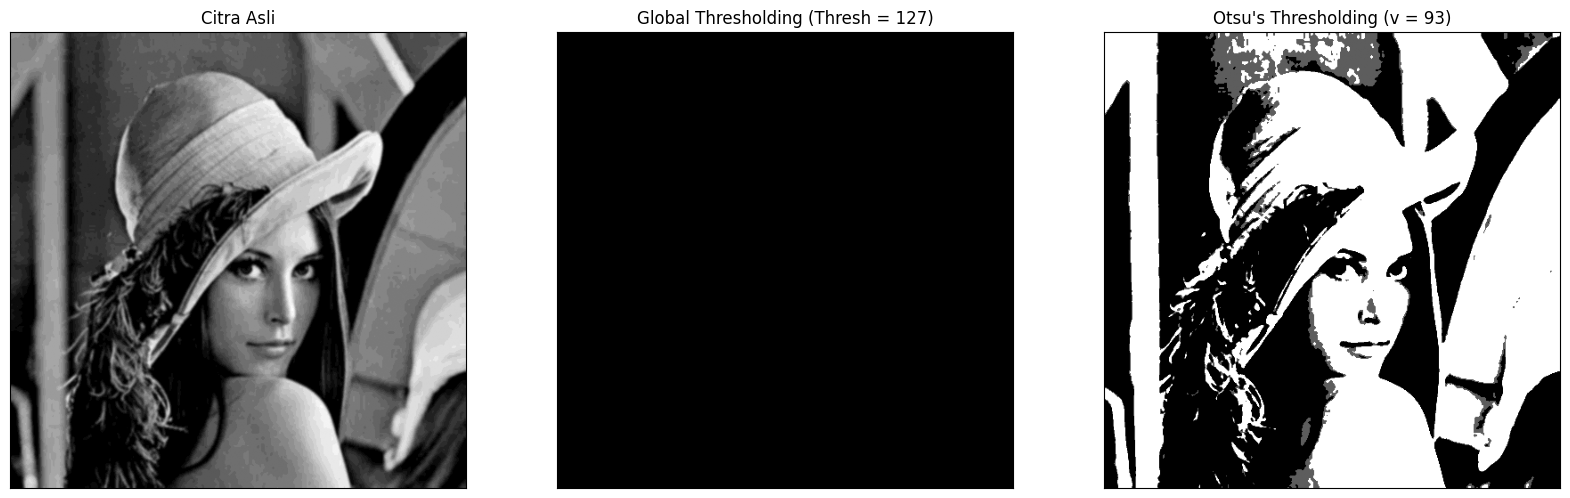

In [5]:
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127
def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight
    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2
    if value > final_value:
        final_thresh = t
        final_value = value
  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh
otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]
plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

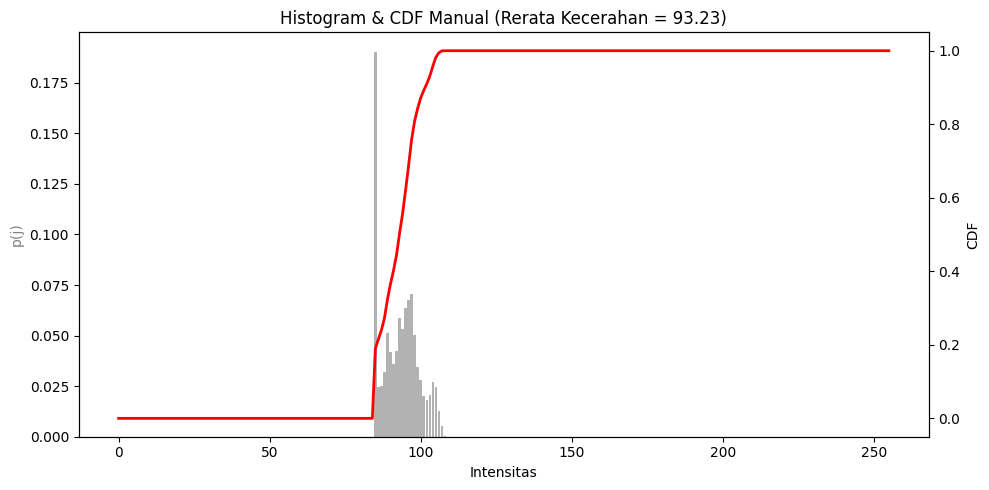

Rerata kecerahan citra:
  /content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg: 93.23


In [6]:
BASE = filename

def histogram_manual(img_gray):
    h = np.zeros(256, dtype=np.int64)
    for y in range(img_gray.shape[0]):
        for x in range(img_gray.shape[1]):
            h[img_gray[y, x]] += 1
    return h

gray = cv.imread(BASE, cv.IMREAD_GRAYSCALE)

if gray is None:
    print(f"Peringatan: Gagal membaca file dari path {BASE}. Periksa kembali.")
else:
    h = histogram_manual(gray)
    p = h / gray.size
    cdf = np.cumsum(p)

    rerata_kecerahan = {BASE: gray.mean()}

    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax2 = ax1.twinx()

    ax1.bar(np.arange(256), p, color='gray', alpha=0.6, label='p(j)')
    ax2.plot(np.arange(256), cdf, color='red', linewidth=2, label='CDF')

    ax1.set_title(f'Histogram & CDF Manual (Rerata Kecerahan = {gray.mean():.2f})')
    ax1.set_xlabel('Intensitas')
    ax1.set_ylabel('p(j)', color='gray')
    ax2.set_ylabel('CDF')

    plt.tight_layout()
    plt.show()

    print('Rerata kecerahan citra:')
    for k, v in rerata_kecerahan.items():
        print(f'  {k}: {v:.2f}')

/tmp/ipykernel_1054/3664756240.py:17: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


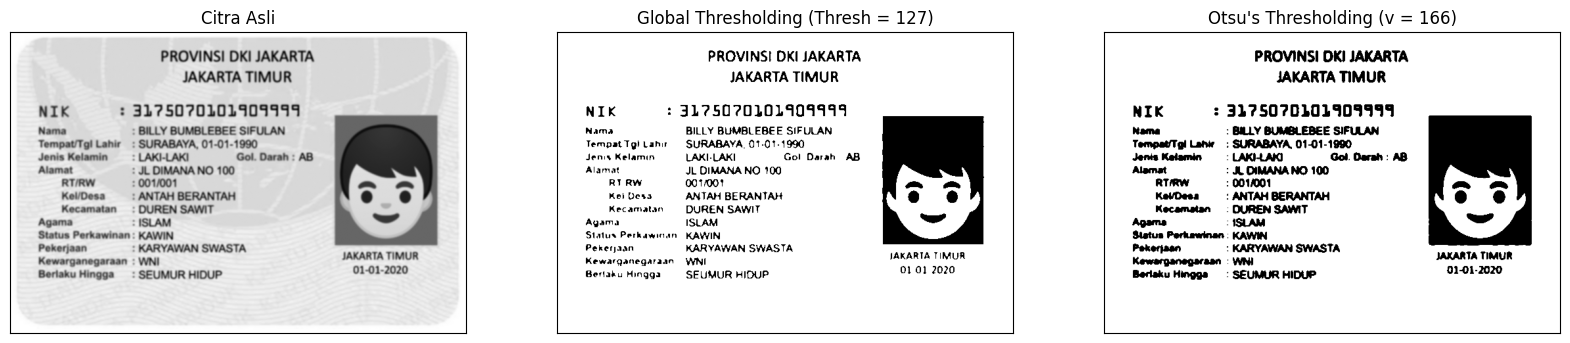

In [7]:
filename = ('/content/drive/MyDrive/PCVK/Images/ktp1.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127
def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight
    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2
    if value > final_value:
        final_thresh = t
        final_value = value
  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh
otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]
plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

Seed di dalam koin (baris, kolom): (36, 43) | intensitas: 159.0
Seed di latar (baris, kolom): (150, 20) | intensitas: 83.0
Seed di tepi koin (baris, kolom): (36, 39) | intensitas: 132.0


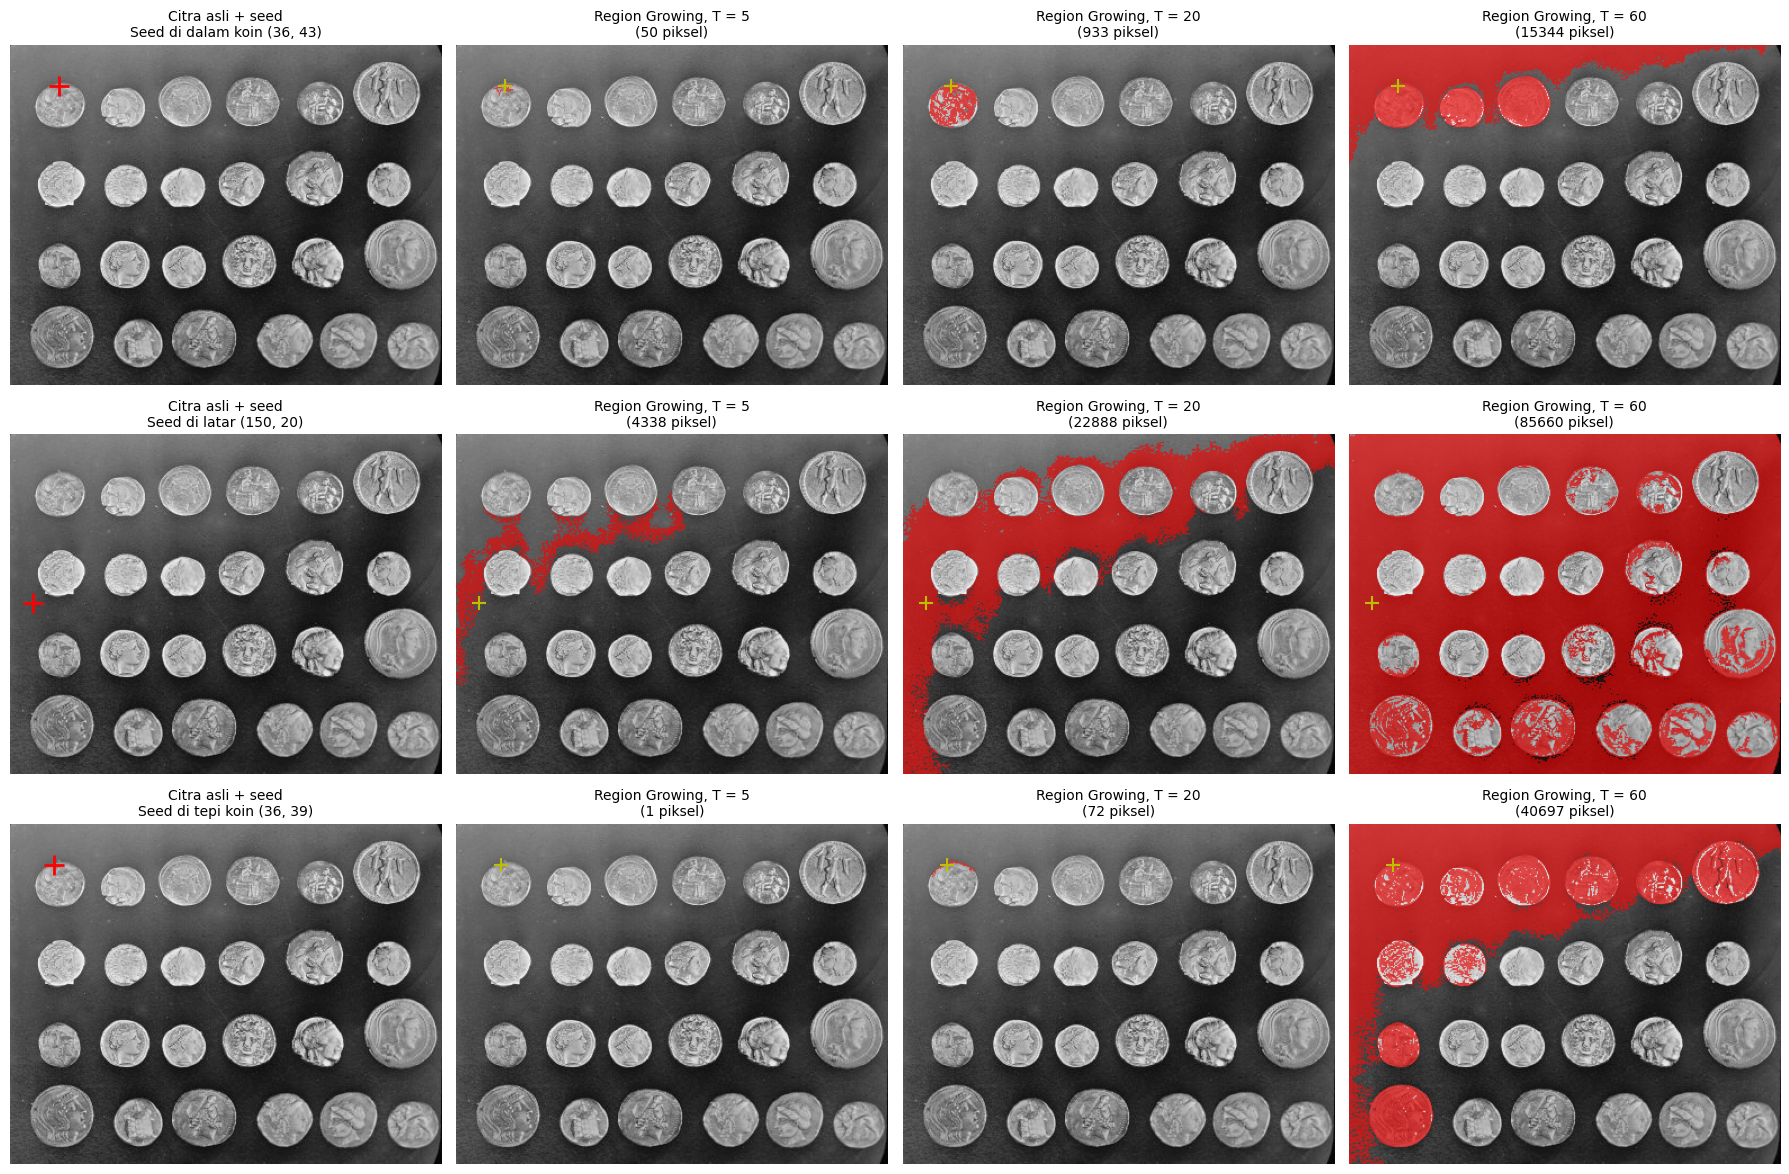

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from skimage import data
from skimage.filters import gaussian, sobel

# ------------------------------------------------------------
# 1. Muat citra
# ------------------------------------------------------------
img = data.coins()                 # grayscale, 303 x 384
img_f = img.astype(float)

# ------------------------------------------------------------
# 2. Region Growing (8-konektivitas, kriteria |I - I_seed| <= T)
# ------------------------------------------------------------
def region_growing(image, seed, T):
    h, w = image.shape
    sr, sc = seed
    seed_val = image[sr, sc]

    mask = np.zeros((h, w), dtype=bool)
    mask[sr, sc] = True
    queue = deque([(sr, sc)])

    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 ( 0, -1),          ( 0, 1),
                 ( 1, -1), ( 1, 0), ( 1, 1)]

    while queue:
        r, c = queue.popleft()
        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not mask[nr, nc]:
                if abs(image[nr, nc] - seed_val) <= T:
                    mask[nr, nc] = True
                    queue.append((nr, nc))
    return mask

# ------------------------------------------------------------
# 3. Tentukan 3 seed
#    - Dalam koin : (36, 43)  (koin kiri-atas, sama seperti contoh)
#    - Latar      : (150, 20)
#    - Tepi koin  : dicari otomatis di baris 36, yaitu posisi
#                   gradien (sobel) terbesar di sisi kiri koin,
#                   sehingga seed benar-benar tepat di batas koin
# ------------------------------------------------------------
edge_map = sobel(gaussian(img_f, sigma=1, preserve_range=True))
row = 36
cols = np.arange(15, 43)                       # sisi kiri koin
edge_col = cols[np.argmax(edge_map[row, cols])]

seeds = {
    "Seed di dalam koin": (36, 43),
    "Seed di latar":      (150, 20),
    "Seed di tepi koin":  (row, int(edge_col)),
}

T_values = [5, 20, 60]

# ------------------------------------------------------------
# 4. Overlay merah
# ------------------------------------------------------------
def overlay(image, mask, alpha=0.6):
    rgb = np.stack([image] * 3, axis=-1).astype(float) / 255.0
    rgb[mask] = (1 - alpha) * rgb[mask] + alpha * np.array([1, 0, 0])
    return rgb

# ------------------------------------------------------------
# 5. Tampilkan: 3 baris (seed) x 4 kolom (asli + T=5, 20, 60)
# ------------------------------------------------------------
fig, axes = plt.subplots(len(seeds), 4, figsize=(18, 12))

for i, (name, seed) in enumerate(seeds.items()):
    print(f"{name} (baris, kolom): {seed} | intensitas: {img_f[seed]}")

    # Kolom 1: citra asli + seed
    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].plot(seed[1], seed[0], "r+", markersize=14, markeredgewidth=2)
    axes[i, 0].set_title(f"Citra asli + seed\n{name} {seed}", fontsize=10)
    axes[i, 0].axis("off")

    # Kolom 2-4: hasil untuk tiap T
    for j, T in enumerate(T_values):
        mask = region_growing(img_f, seed, T)
        ax = axes[i, j + 1]
        ax.imshow(overlay(img, mask))
        ax.plot(seed[1], seed[0], "y+", markersize=10, markeredgewidth=1.5)
        ax.set_title(f"Region Growing, T = {T}\n({mask.sum()} piksel)", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

Seed di dalam koin (baris, kolom): (36, 43) | intensitas: 159.0
Seed di latar (baris, kolom): (150, 20) | intensitas: 83.0
Seed di tepi koin (baris, kolom): (36, 39) | intensitas: 132.0


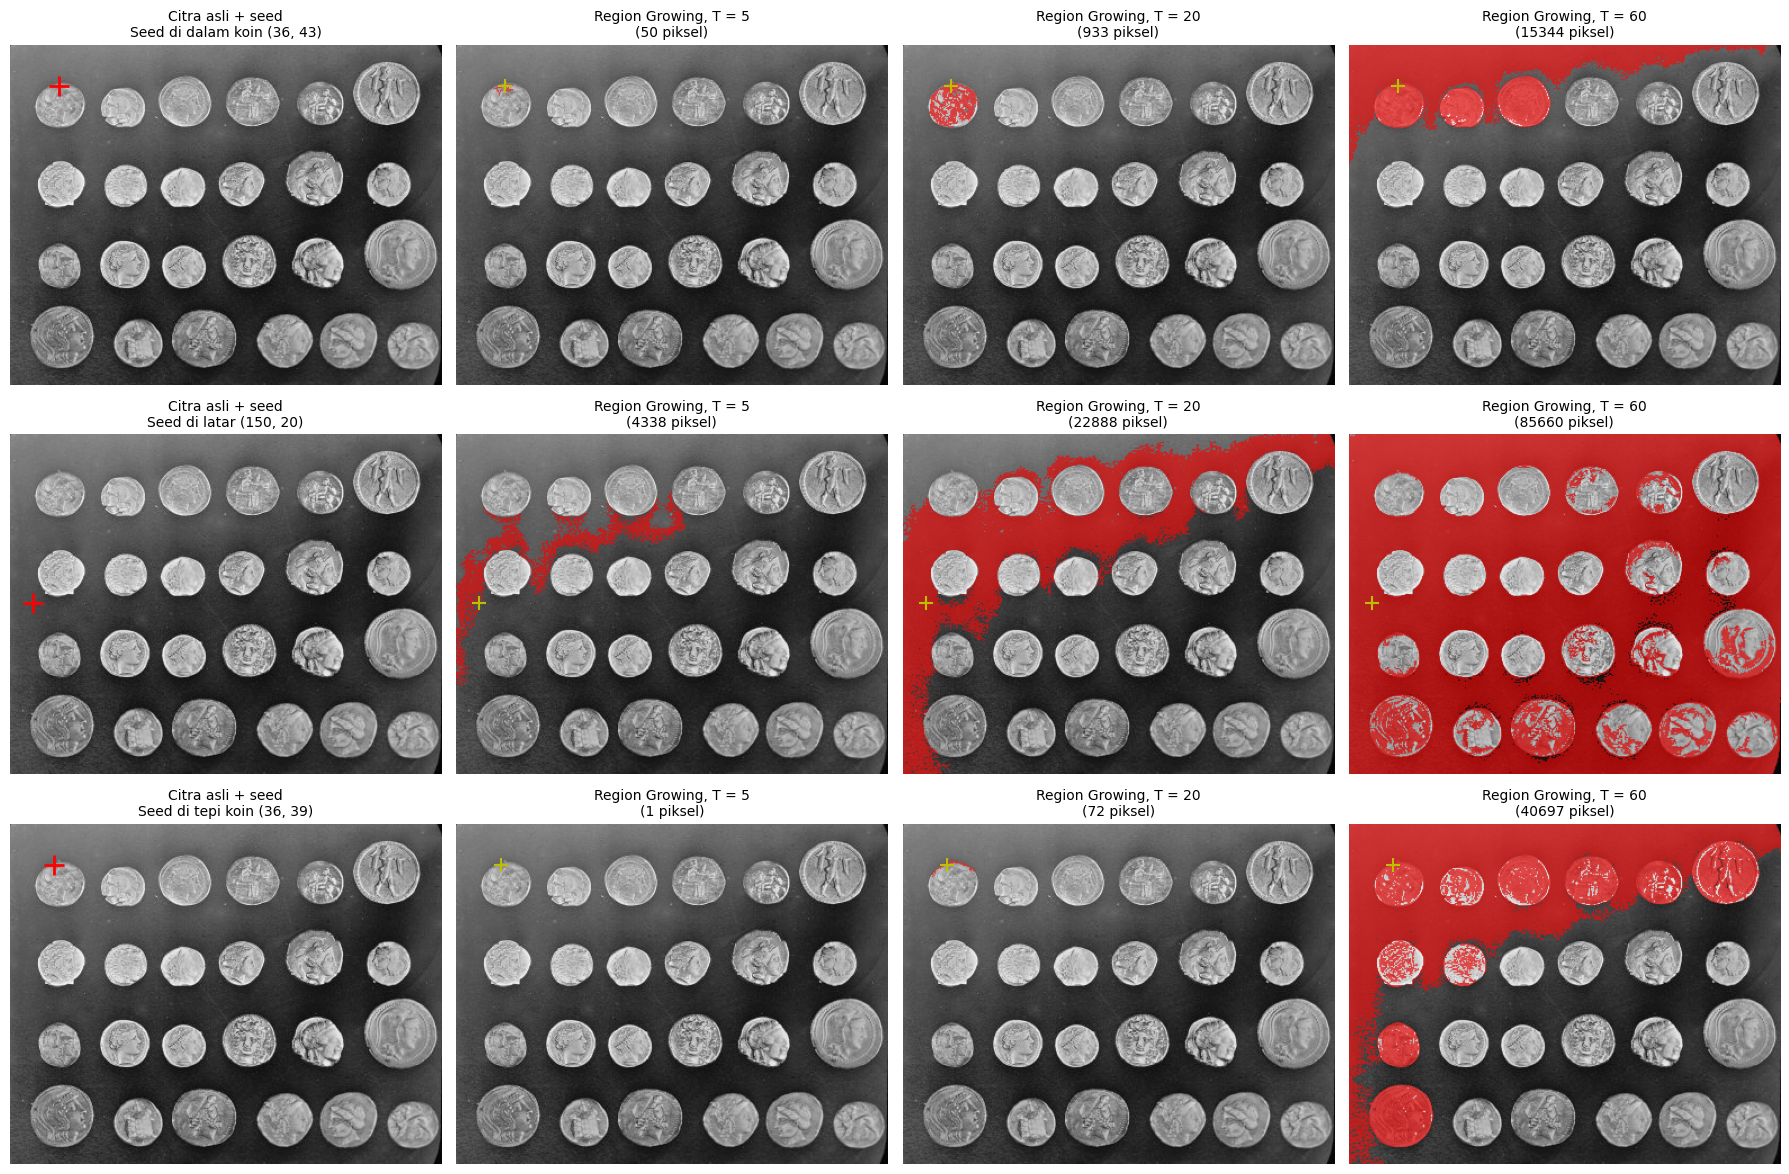

In [9]:
gray = data.coins()
seed = (121, 63)

region = flood(
    gray,
    seed_point=seed,
    tolerance=20,
    connectivity=1
)

fig, axes = plt.subplots(len(seeds), 4, figsize=(18, 12))

for i, (name, seed) in enumerate(seeds.items()):
    print(f"{name} (baris, kolom): {seed} | intensitas: {img_f[seed]}")

    # Kolom 1: citra asli + seed
    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].plot(seed[1], seed[0], "r+", markersize=14, markeredgewidth=2)
    axes[i, 0].set_title(f"Citra asli + seed\n{name} {seed}", fontsize=10)
    axes[i, 0].axis("off")

    # Kolom 2-4: hasil untuk tiap T
    for j, T in enumerate(T_values):
        mask = region_growing(img_f, seed, T)
        ax = axes[i, j + 1]
        ax.imshow(overlay(img, mask))
        ax.plot(seed[1], seed[0], "y+", markersize=10, markeredgewidth=1.5)
        ax.set_title(f"Region Growing, T = {T}\n({mask.sum()} piksel)", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

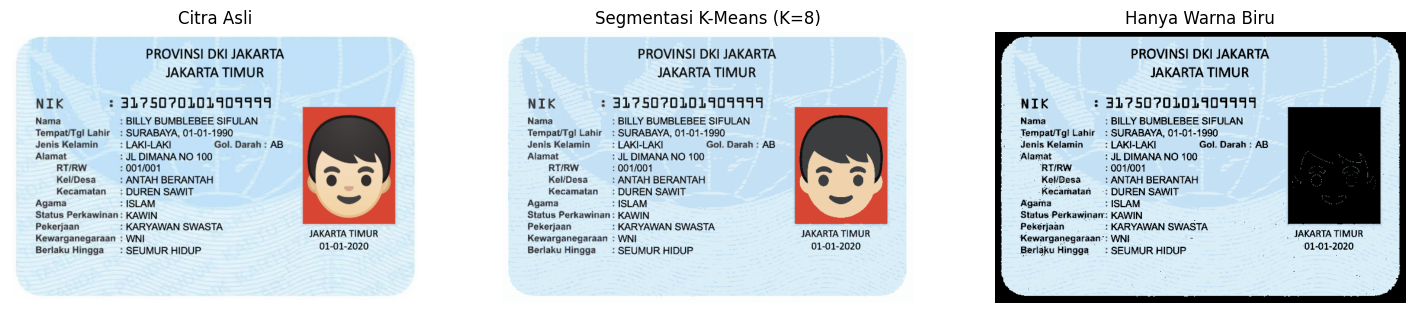

In [12]:
from sklearn.cluster import KMeans

# Baca citra dan ubah ke RGB
filename = ('/content/drive/MyDrive/PCVK/Images/ktp1.jpg')
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# K-Means dengan K = 8
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Ubah hasil K-Means ke HSV, lalu ambil hanya warna biru
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]

kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

hanya_biru = np.zeros_like(segmented_img)       # semua hitam
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]   # warna biru dikembalikan

# Tampilkan
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
hasil = [img, segmented_img, hanya_biru]

plt.figure(figsize=(18,5))
for i in range(3):
    plt.subplot(1,3,i+1)
    plt.imshow(hasil[i])
    plt.title(titles[i])
    plt.axis('off')
plt.show()